## Cohort Heatmap 
- User Retention Heatmap
- Revenue per Retained User
- Relative RPRU Growth by Cohort
- Cohort LTV Heatmap

## Исходные данные для построения

In [1]:
import pandas as pd
# Настройка отображения
pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.width', None)
pd.set_option('display.max_columns', None)

In [2]:
user_retention = pd.read_parquet('user_retention.parquet')
rpru_table = pd.read_parquet('rpru_table.parquet')
ltv_table = pd.read_parquet('ltv_table.parquet')

In [3]:
print(user_retention)

cohort_index   0         1         2         3         4         5         6         7         8         9         10
cohort_month                                                                                                         
2021-07       1.0  0.333876  0.345277  0.317590  0.328990  0.294788  0.280130  0.289902  0.270358  0.254072  0.239414
2021-08       1.0  0.284257  0.298834  0.253644  0.252187  0.233236  0.214286  0.204082  0.202624  0.172012       NaN
2021-09       1.0  0.301435  0.244019  0.223285  0.247209  0.186603  0.204147  0.189793  0.178628       NaN       NaN
2021-10       1.0  0.245115  0.266430  0.227353  0.202487  0.181172  0.179396  0.158082       NaN       NaN       NaN
2021-11       1.0  0.275100  0.204819  0.222892  0.198795  0.174699  0.176707       NaN       NaN       NaN       NaN
2021-12       1.0  0.190570  0.200393  0.161100  0.155206  0.149312       NaN       NaN       NaN       NaN       NaN
2022-01       1.0  0.218341  0.216157  0.189956  0.17030

In [4]:
print(rpru_table)

cohort_index    0     1     2     3     4     5     6     7     8     9     10
cohort_month                                                                  
2021-07-01    1.29  1.90  1.53  2.04  1.91  1.78  2.03  1.63  2.13  1.74  1.85
2021-08-01    1.14  1.26  1.29  1.38  1.36  1.38  1.44  1.89  1.19  1.34   NaN
2021-09-01    1.30  1.63  1.50  1.70  1.36  1.48  1.71  1.36  1.37   NaN   NaN
2021-10-01    1.35  1.61  1.61  1.71  1.47  1.20  1.33  1.24   NaN   NaN   NaN
2021-11-01    1.44  1.31  1.56  1.28  1.20  1.22  1.08   NaN   NaN   NaN   NaN
2021-12-01    1.26  1.33  1.33  1.06  1.26  1.05   NaN   NaN   NaN   NaN   NaN
2022-01-01    1.26  1.46  2.08  1.34  1.33   NaN   NaN   NaN   NaN   NaN   NaN
2022-02-01    1.36  1.42  1.35  1.29   NaN   NaN   NaN   NaN   NaN   NaN   NaN
2022-03-01    1.56  1.17  1.47   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN
2022-04-01    1.31  2.13   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN
2022-05-01    1.34   NaN   NaN   NaN   NaN   NaN   N

In [5]:
print(ltv_table)

cohort_index    0     1     2     3     4     5     6     7     8     9     10
cohort_month                                                                  
2021-07       1.29  1.92  2.45  3.10  3.73  4.25  4.82  5.30  5.87  6.31  6.76
2021-08       1.14  1.49  1.88  2.23  2.57  2.89  3.20  3.59  3.83  4.06   NaN
2021-09       1.30  1.79  2.16  2.54  2.88  3.15  3.50  3.76  4.00   NaN   NaN
2021-10       1.35  1.74  2.17  2.56  2.85  3.07  3.31  3.50   NaN   NaN   NaN
2021-11       1.44  1.80  2.12  2.41  2.65  2.86  3.05   NaN   NaN   NaN   NaN
2021-12       1.26  1.51  1.78  1.95  2.14  2.30   NaN   NaN   NaN   NaN   NaN
2022-01       1.26  1.58  2.03  2.28  2.51   NaN   NaN   NaN   NaN   NaN   NaN
2022-02       1.36  1.77  1.98  2.22   NaN   NaN   NaN   NaN   NaN   NaN   NaN
2022-03       1.56  1.81  2.07   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN
2022-04       1.31  1.74   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN
2022-05       1.34   NaN   NaN   NaN   NaN   NaN   N

## Код для построения

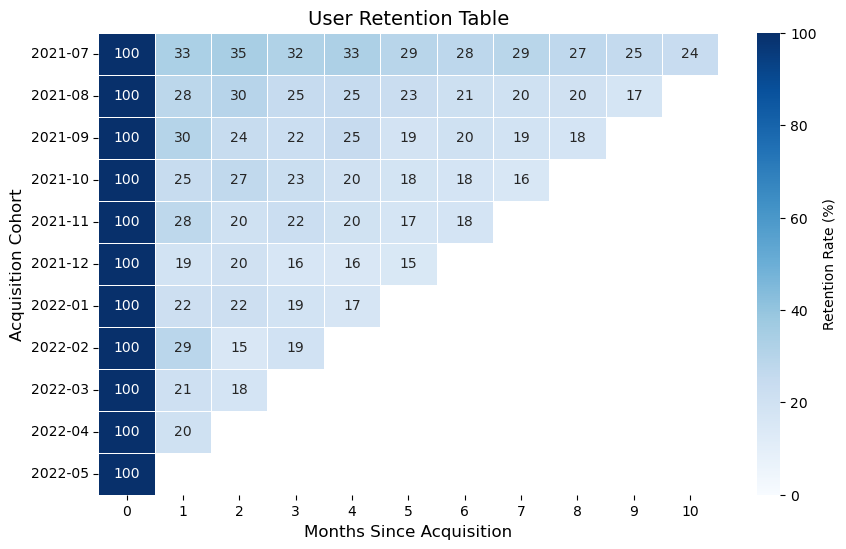

In [6]:
# =====================================================
# IMPORTS
# =====================================================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# =====================================================
# PLOT
# =====================================================

plt.figure(figsize=(10, 6))
plt.title('User Retention Table', fontsize=14)

retention_display = user_retention * 100

sns.heatmap(
    data=retention_display,
    annot=True,
    fmt='.0f',
    linewidths=.4,
    cmap='Blues',
        vmin=0,
    vmax=100,
    cbar_kws={'label': 'Retention Rate (%)'}
)

plt.yticks(rotation=0)  # optional cleaner look
plt.xlabel('Months Since Acquisition', fontsize=12)
plt.ylabel('Acquisition Cohort', fontsize=12)
plt.savefig("user_retention_table.png", dpi=300, bbox_inches="tight")
plt.show()

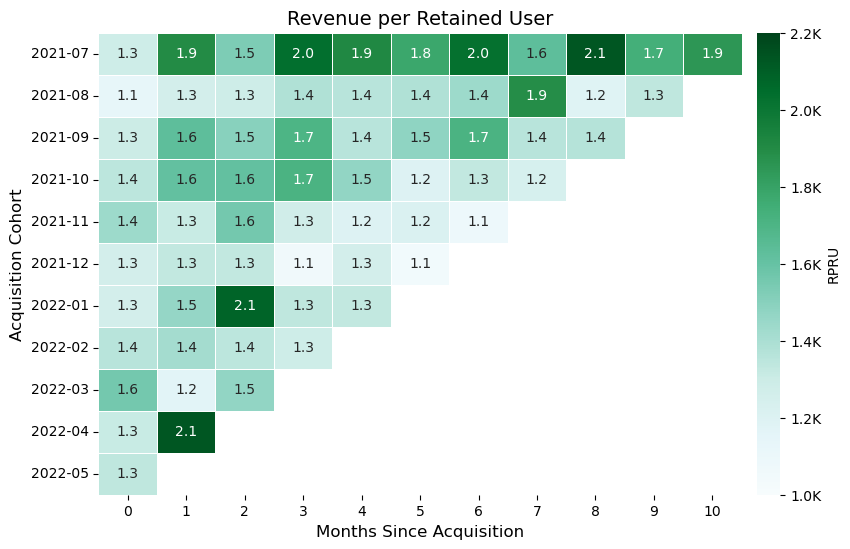

In [7]:
# =====================================================
# PLOT
# =====================================================

rpru_table.index = rpru_table.index.strftime('%Y-%m')

fig, ax = plt.subplots(figsize=(10, 6))

heatmap = sns.heatmap(
    rpru_table,
    annot=True,
    fmt='.1f',
    cmap='BuGn',
    linewidths=.4,
    vmin=1.0,
    vmax=2.2,
    cbar=False
   # cbar_kws={'label': 'RPRU (thousand rub)'}
)

# Создаем colorbar вручную
cbar = fig.colorbar(heatmap.get_children()[0], ax=ax, label='RPRU',  pad=0.02)

# =====================================================
# ПОЛУЧАЕМ COLORBAR И УБИРАЕМ КОНТУР
# =====================================================

cbar = heatmap.collections[0].colorbar  # получаем colorbar из heatmap
cbar.outline.set_visible(False)         # ← убираем контур!

# =====================================================
# ФОРМАТИРОВАНИЕ COLORBAR
# =====================================================
from matplotlib.ticker import FuncFormatter
def millions_formatter(x, pos):
    return f'{x:.1f}K'  # ← один знак после запятой

cbar.ax.yaxis.set_major_formatter(FuncFormatter(millions_formatter))

plt.title('Revenue per Retained User', fontsize=14)
plt.xlabel('Months Since Acquisition', fontsize=12)
plt.ylabel('Acquisition Cohort', fontsize=12)
plt.savefig("revenue_per_retained_user.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
# =====================================================
# PLOT
# =====================================================

rpru_growth = rpru_table.divide(rpru_table[0], axis=0)

rpru_growth.index = rpru_growth.index.strftime('%Y-%m')

plt.figure(figsize=(10, 6))

sns.heatmap(
    rpru_growth,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    center=1,
    linewidths=.4,
    annot_kws={'fontsize': 10},
    # Добавляем подпись к цветовой шкале (Color Bar)
    cbar_kws={'label': 'Index (1.0 = Base Month)'} 
)

plt.title('Relative RPRU Growth by Cohort', fontsize=14)
plt.xlabel('Months Since Acquisition')
plt.ylabel('Acquisition Cohort')
plt.savefig("rpru_normalized.png", dpi=300, bbox_inches="tight")
plt.show()

AttributeError: 'Index' object has no attribute 'strftime'

In [ ]:
# =====================================================
# PLOT COHORT LTV MATRIX
# =====================================================

fig, ax = plt.subplots(figsize=(10, 6))



heatmap = sns.heatmap(
    ltv_table,
    cmap='BuGn',
    linewidths=.4,
    annot=True,
    fmt='.1f',
    cbar=False,
    vmin=1.1,
    vmax=6.9,
)

# =====================================================
# СОЗДАЕМ COLORBAR ВРУЧНУЮ
# =====================================================

# Параметр pad контролирует расстояние от графика
cbar = fig.colorbar(
    heatmap.get_children()[0], 
    ax=ax, 
    label='LTV',
    pad=0.02#,           # ← УМЕНЬШАЕМ ОТСТУП
    #fraction=0.18,     # ← уменьшаем ширину colorbar
    #aspect=30           # ← соотношение сторон
)

# =====================================================
# ФОРМАТИРОВАНИЕ COLORBAR В ФОРМАТЕ "0M"
# =====================================================

def millions_formatter(x, pos):
    return f'{x:.0f}K'

cbar.ax.yaxis.set_major_formatter(FuncFormatter(millions_formatter))

# =====================================================
# УБИРАЕМ РАМКУ COLORBAR
# =====================================================

cbar.outline.set_visible(False)  # ← убираем черный контур!


ax.set_title('Cohort LTV Table', fontsize=14)
ax.set_xlabel('Months Since Acquisition', fontsize=12)
ax.set_ylabel('Acquisition Cohort', fontsize=12)

plt.savefig("cohort_ltv_table.png", dpi=300, bbox_inches="tight")

plt.show()